# 1a.1–1a.2 — Autoencoder architecture and optimisation study

Goal: learn all 32 patterns of `font.h` (7x5 pixels) through a **2-dimensional latent space**, with **at most 1 wrong pixel per letter** after rounding the output.

The network is implemented from scratch with numpy in `src/tp5/autoencoder.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from tp5.autoencoder import Adam, Autoencoder
from tp5.data import load_font, pixel_errors, show_letters
from tp5.study import run_config, summarize

X, chars = load_font()
X = X.astype(float)
X.shape

(32, 35)

## 1. Proposed architecture

| Layer | Size | Activation |
|---|---|---|
| Input | 35 | – |
| Encoder hidden 1 | 20 | tanh |
| Encoder hidden 2 | 10 | tanh |
| **Latent** | **2** | identity (linear) |
| Decoder hidden 1 | 10 | tanh |
| Decoder hidden 2 | 20 | tanh |
| Output | 35 | sigmoid |

Design choices:

- **Mirrored encoder/decoder** (35-20-10-2-10-20-35): the decoder has to undo the compression, so it gets the same capacity as the encoder.
- **Linear latent layer**: a bounded activation (tanh/sigmoid) would squeeze the 32 codes into a small box; a linear code lets the letters spread out in the plane.
- **Sigmoid output + binary cross-entropy loss**: pixels are 0/1, so each output is a Bernoulli probability. With this pair the output gradient is simply `y_hat - y`, which does not vanish when the sigmoid saturates on a wrong pixel (unlike MSE).
- **Xavier initialisation** (He for ReLU), biases at zero.
- **Adam** optimiser, full batch (all 32 letters per update).
- Training stops as soon as every letter has at most 1 wrong pixel.

stopped after 350 epochs
wrong pixels per letter: max 1, total 4


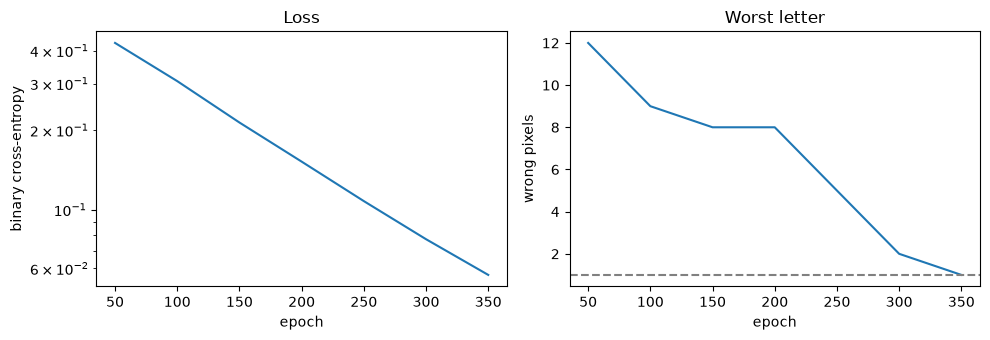

In [2]:
ae = Autoencoder(hidden=(20, 10), activation="tanh", seed=0)
history = ae.fit(X, epochs=20_000, optimizer=Adam(lr=1e-2), log_every=50, stop_at_pixels=1)
errors = pixel_errors(X, ae.reconstruct(X))
print(f"stopped after {history['epoch'][-1]} epochs")
print(f"wrong pixels per letter: max {errors.max()}, total {errors.sum()}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(history["epoch"], history["loss"])
ax1.set(xlabel="epoch", ylabel="binary cross-entropy", yscale="log", title="Loss")
ax2.plot(history["epoch"], history["max_pixel_error"])
ax2.axhline(1, color="gray", ls="--")
ax2.set(xlabel="epoch", ylabel="wrong pixels", title="Worst letter")
fig.tight_layout()

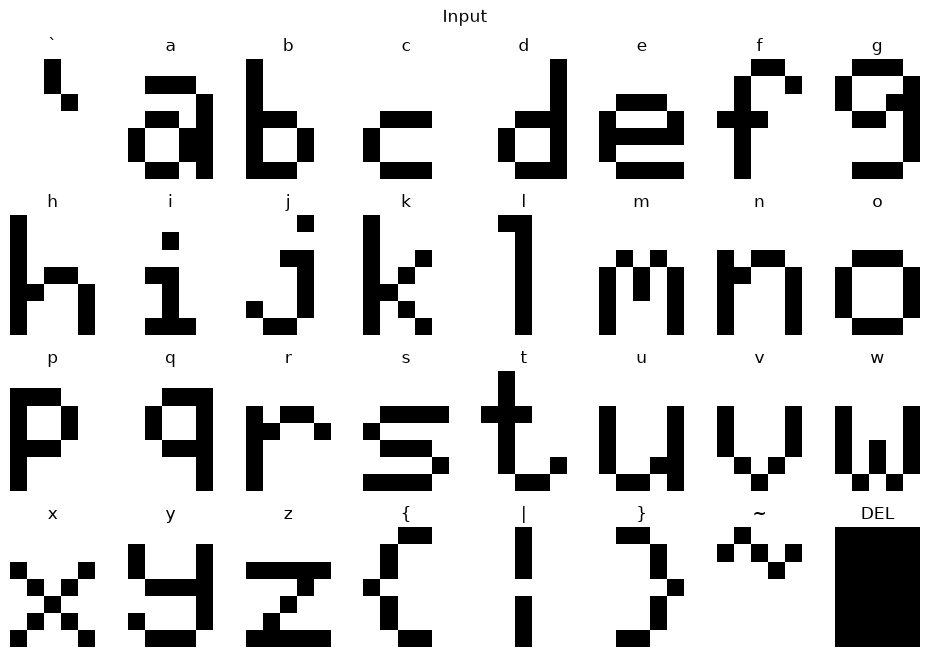

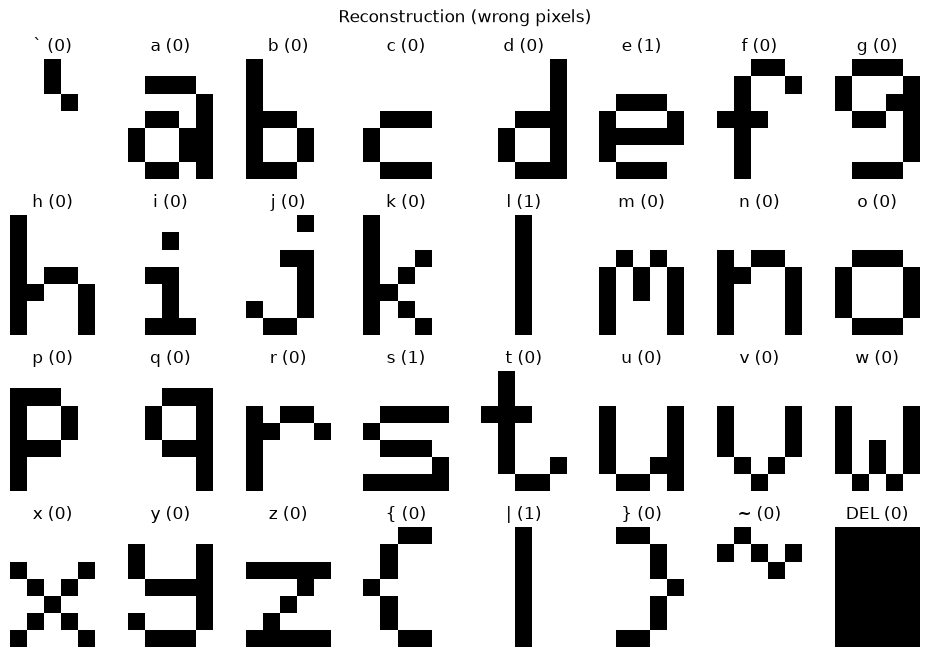

In [3]:
show_letters(X, titles=chars)
plt.suptitle("Input", y=1.02)
show_letters(np.round(ae.reconstruct(X)), titles=[f"{c} ({e})" for c, e in zip(chars, errors)])
plt.suptitle("Reconstruction (wrong pixels)", y=1.02);

## 2. Study of architectures and optimisation techniques

Each configuration is trained with **5 seeds** (different weight initialisations), for at most 20 000 epochs, stopping once every letter has at most 1 wrong pixel. We report:

- **success**: fraction of seeds that learn all 32 letters,
- **median epochs** of the successful runs,
- **mean letters ok**: average number of letters with at most 1 wrong pixel.

Unless stated otherwise the baseline is the architecture above with Adam (lr = 1e-3), full batch. The whole study takes about 10 minutes to run.

In [4]:
def show_study(rows, key, title):
    summary = summarize(rows, key)
    print(f"{key:>16} | success | median epochs | mean letters ok")
    for s in summary:
        epochs = "-" if s["median_epochs"] is None else f"{s['median_epochs']:.0f}"
        print(f"{s[key]:>16} | {s['success_rate']:7.0%} | {epochs:>13} | {s['mean_letters_ok']:15.1f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    for value in dict.fromkeys(str(r[key]) for r in rows):
        h = next(r for r in rows if str(r[key]) == value)["history"]  # seed 0
        ax1.plot(h["epoch"], h["loss"], label=value)
        ax2.plot(h["epoch"], h["max_pixel_error"], label=value)
    ax1.set(xlabel="epoch", ylabel="loss", yscale="log", title=f"{title}: loss (seed 0)")
    ax2.axhline(1, color="gray", ls="--")
    ax2.set(xlabel="epoch", ylabel="wrong pixels", yscale="symlog", title=f"{title}: worst letter (seed 0)")
    ax2.legend(fontsize=8)
    fig.tight_layout()

### 2.1 Depth and width of the hidden layers

          hidden | success | median epochs | mean letters ok
              () |      0% |             - |             2.8
            (5,) |      0% |             - |             3.8
           (10,) |     20% |         11800 |            24.4
           (20,) |     80% |          6800 |            31.6
        (20, 10) |    100% |          3700 |            32.0
    (30, 20, 10) |    100% |          2200 |            32.0
        (40, 20) |    100% |          1600 |            32.0


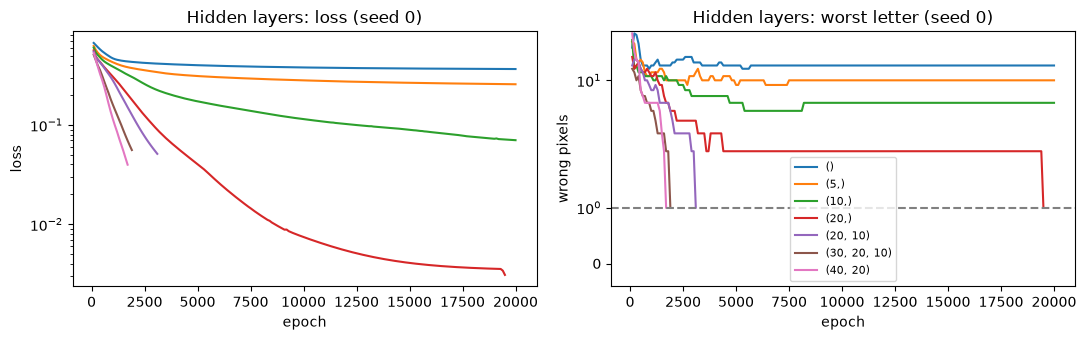

In [5]:
rows_hidden = sum((run_config(X, hidden=h) for h in [(), (5,), (10,), (20,), (20, 10), (30, 20, 10), (40, 20)]), [])
show_study(rows_hidden, "hidden", "Hidden layers")

- Without hidden layers (35-2-35) or with only 5 units, the network learns just ~3 letters: the encoder is (almost) linear, so it can only project the letters onto a plane, and the decoder cannot separate 32 patterns from that.
- One hidden layer of 10 units gets most letters but rarely all of them; 20 units succeeds 4 out of 5 times.
- Two or more hidden layers solve the task for every seed, and wider/deeper networks need fewer epochs (35-40-20-2-20-40-35 is the fastest). The extra non-linear layers let the decoder carve the 2D plane into 32 regions, one per letter.

### 2.2 Activation function of the hidden layers

      activation | success | median epochs | mean letters ok
            tanh |    100% |          3700 |            32.0
            relu |     80% |          2000 |            31.8
         sigmoid |    100% |          9000 |            32.0


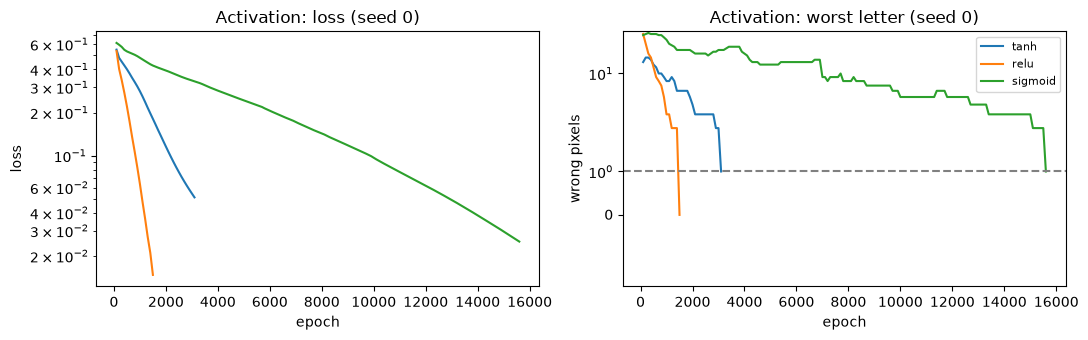

In [6]:
rows_act = sum((run_config(X, activation=a) for a in ["tanh", "relu", "sigmoid"]), [])
show_study(rows_act, "activation", "Activation")

- **tanh** is reliable (5/5) and reasonably fast.
- **ReLU** is the fastest when it works, but fails for 1 seed: with only 10 units next to the 2D bottleneck, some units die (always output 0) and the network loses capacity it cannot recover.
- **sigmoid** also reaches 5/5 but is ~2.5x slower: its outputs are not zero-centred and its derivative is at most 0.25, so gradients shrink as they pass through the layers.

### 2.3 Optimiser and learning rate

  optimizer / lr | success | median epochs | mean letters ok
         sgd 0.5 |     80% |         11650 |            31.8
           sgd 1 |    100% |         14700 |            32.0
   momentum 0.05 |     80% |          8800 |            31.8
    momentum 0.2 |    100% |          2200 |            32.0
     adam 0.0001 |     20% |         18900 |            29.2
      adam 0.001 |    100% |          3700 |            32.0
       adam 0.01 |    100% |           400 |            32.0


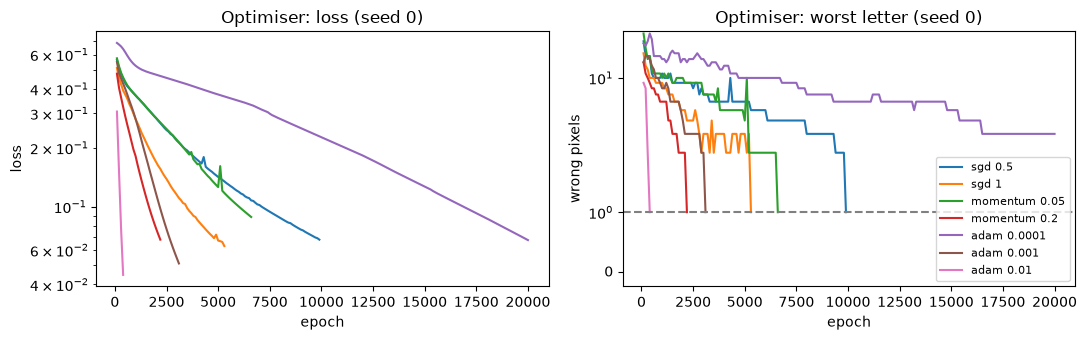

In [7]:
configs = [("sgd", 0.5), ("sgd", 1.0), ("momentum", 0.05), ("momentum", 0.2), ("adam", 1e-4), ("adam", 1e-3), ("adam", 1e-2)]
rows_opt = sum((run_config(X, optimizer=o, lr=lr) for o, lr in configs), [])
for r in rows_opt:
    r["optimizer / lr"] = f"{r['optimizer']} {r['lr']:g}"
show_study(rows_opt, "optimizer / lr", "Optimiser")

- Plain **gradient descent** works but is slow (~12 000–15 000 epochs). With larger learning rates (we also tried 2, 5, 20 and 50) it diverges or gets stuck with saturated units.
- **Momentum** speeds it up a lot (lr 0.2: ~2 200 epochs), but becomes unstable above that (lr 0.5 failed for one of two test seeds).
- **Adam** adapts the step size per weight, so it is much less sensitive to the scale of the gradients. lr = 1e-4 is too small to finish in 20 000 epochs, 1e-3 is reliable, and **1e-2 is the fastest (~400 epochs) and still 5/5**. That is why the final model uses Adam with lr = 1e-2.

### 2.4 Batch size

      batch_size | success | median epochs | mean letters ok
              32 |    100% |          3700 |            32.0
               8 |    100% |          5300 |            32.0
               1 |    100% |          1500 |            32.0


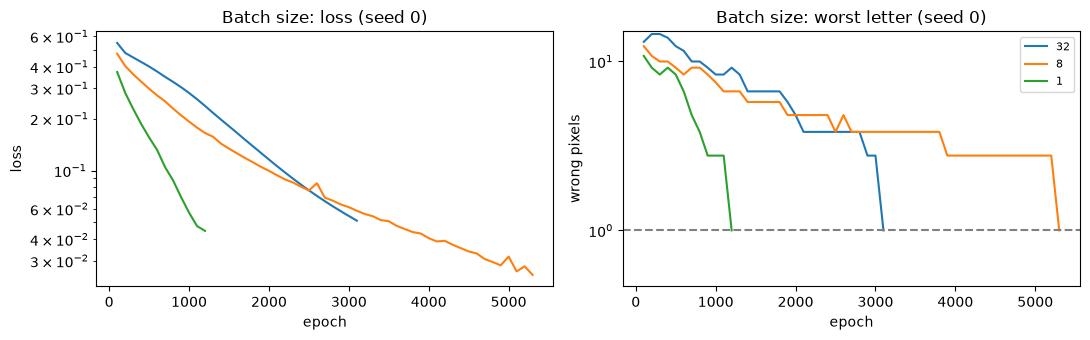

In [8]:
rows_batch = sum((run_config(X, batch_size=b) for b in [None, 8, 1]), [])
show_study(rows_batch, "batch_size", "Batch size")

All batch sizes learn the full set. The number of weight updates per epoch is 32 / batch size: online training (batch 1) needs the fewest epochs but makes 32x more updates per epoch, so per update full batch is the most efficient. With only 32 patterns the full gradient is cheap, so we use full batch.

## 3. Why small networks only learn a subset

For the configurations that fail, look at which letters are not learned. Below is the 35-5-2-5-35 network (seed 0).

letters with <= 1 wrong pixel: 2 / 32


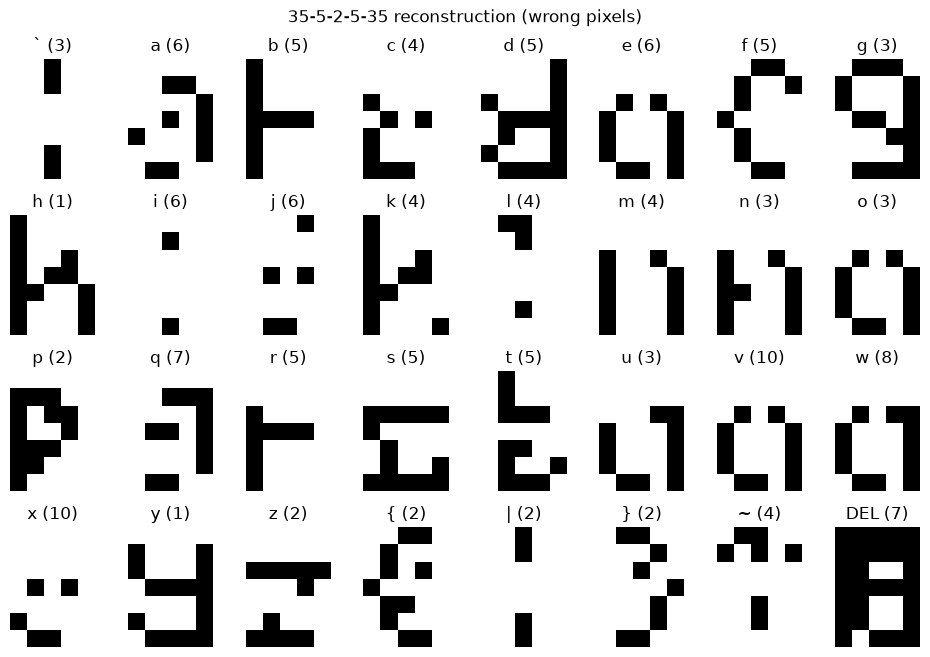

In [9]:
small = Autoencoder(hidden=(5,), seed=0)
small.fit(X, epochs=20_000, optimizer=Adam(lr=1e-3), log_every=1000)
small_errors = pixel_errors(X, small.reconstruct(X))
print(f"letters with <= 1 wrong pixel: {np.sum(small_errors <= 1)} / 32")
show_letters(np.round(small.reconstruct(X)), titles=[f"{c} ({e})" for c, e in zip(chars, small_errors)])
plt.suptitle("35-5-2-5-35 reconstruction (wrong pixels)", y=1.02);

The small decoder can only produce a few "prototype" shapes: it maps the 2D code through 5 tanh units, which is not enough to bend the plane into 32 distinct outputs. Similar letters collapse onto the same average shape, so only the most distinctive letters are reconstructed correctly. Adding a hidden layer (or making it wide enough) gives the decoder the capacity to separate all 32 letters, which is why every network with two hidden layers reaches the goal.

## Conclusions

- **Architecture**: 35-20-10-2-10-20-35 with tanh hidden layers, a linear 2D latent layer and a sigmoid output learns all 32 letters with at most 1 wrong pixel, for every seed tried.
- **Capacity** is the main factor: networks without hidden layers, or with a single small one, only learn a subset because the decoder cannot map a 2D code onto 32 different patterns.
- **Loss**: binary cross-entropy with a sigmoid output fits binary pixels and avoids vanishing gradients at the output.
- **Optimiser**: Adam is the most robust choice; lr = 1e-2 converges in a few hundred epochs. Momentum is competitive when tuned, plain gradient descent is slow.
- **Activation**: tanh is the most reliable; ReLU is fast but can lose units, sigmoid is slow.